# Segmentación de suelo transitable con Graph Cut


| Método | Modelo de color | Corte |
|---|---|---|
| **GrabCut** (`cv2.grabCut`) | GMM inicializado con semillas y zona incierta | Interno de OpenCV |
| **PyMaxflow** (propio) | Histograma 3D entrenado **solo con semillas** | s-t min-cut con energía propia |

Al terminar genera, dentro de `resultados/`:

- `metricas_por_frame.csv` y `resumen.csv`
- `barrido_lambda.csv`
- `figuras/iou_por_frame.png` y `figuras/mapas_error.png`
- `videos/comparacion_maze.mp4` y `videos/errores_maze.mp4`

## 1. Configuración

In [ ]:
import importlib
import shutil
import subprocess
import sys
from pathlib import Path

import cv2
import maxflow
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "segmentacion.py").exists():
    candidatos = [p.parent for p in RAIZ.rglob("segmentacion.py") if (p.parent / "datos").exists()]
    if not candidatos:
        raise FileNotFoundError("Abre el notebook desde la carpeta graph_cut_suelo_demo")
    RAIZ = candidatos[0]

sys.path.insert(0, str(RAIZ))
import segmentacion as seg
importlib.reload(seg)

DIR_RGB = RAIZ / "datos" / "maze" / "rgb"
DIR_GT = RAIZ / "datos" / "maze" / "gt"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_VIDEOS = DIR_RESULTADOS / "videos"
for carpeta in (DIR_FIGURAS, DIR_VIDEOS):
    carpeta.mkdir(parents=True, exist_ok=True)

TAM_PROCESO = (160, 120)
TAM_PANEL = (320, 240)
FPS_VIDEO = 30
SEMILLA = 0

COLOR_GRABCUT = "#eb6834"
COLOR_MAXFLOW = "#2a78d6"
SUPERFICIE = "#fcfcfb"
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "text.color": TEXTO, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.edgecolor": "#c3c2b7", "font.size": 11,
})

print(f"Python {sys.version.split()[0]} | OpenCV {cv2.__version__} | NumPy {np.__version__} | PyMaxflow {maxflow.__version__}")
print("ROS cargado:", any(m == "rclpy" or m.startswith("rclpy.") for m in sys.modules))

Python 3.10.13 | OpenCV 5.1.0 | NumPy 2.2.6 | PyMaxflow 1.3.2
ROS cargado: False


## 2. Datos

Cada par es una imagen RGB y su ground truth con **el mismo nombre** (el timestamp de la simulación). En el ground truth, `1` es suelo y `0` es todo lo demás.

Pares: 886 | RGB (240, 320, 3) | GT (240, 320) | valores GT [0, 1]


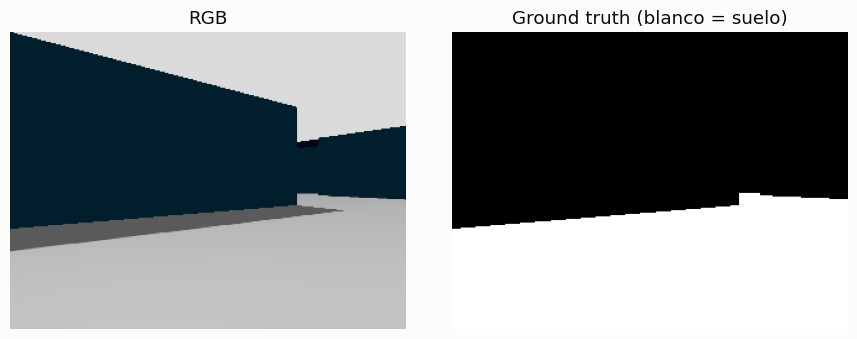

In [2]:
stamps_rgb = {p.stem for p in DIR_RGB.glob("*.png")}
stamps_gt = {p.stem for p in DIR_GT.glob("*.png")}
stamps = sorted(stamps_rgb & stamps_gt)

if not stamps or stamps_rgb != stamps_gt:
    raise RuntimeError(f"Pares incompletos: {len(stamps_rgb)} RGB, {len(stamps_gt)} GT, {len(stamps)} comunes")

def leer_par(stamp):
    rgb = cv2.imread(str(DIR_RGB / f"{stamp}.png"))
    gt = cv2.imread(str(DIR_GT / f"{stamp}.png"), cv2.IMREAD_UNCHANGED)
    if rgb is None or gt is None:
        raise IOError(f"No se pudo leer el par {stamp}")
    return rgb, gt

rgb, gt = leer_par(stamps[0])
print(f"Pares: {len(stamps)} | RGB {rgb.shape} | GT {gt.shape} | valores GT {np.unique(gt).tolist()}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].imshow(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)); ax[0].set_title("RGB")
ax[1].imshow(gt, cmap="gray", vmin=0, vmax=1); ax[1].set_title("Ground truth (blanco = suelo)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. El método con PyMaxflow

Se busca la etiqueta $L_p$ (suelo o fondo) de cada píxel que minimiza:

$$E(L)=\sum_p D_p(L_p)+\lambda\sum_{(p,q)\in\mathcal N} w_{pq}\,[L_p\neq L_q]$$

- **Término de datos:** $D_p(c)=-\log P(I_p\mid c)$, con un histograma BGR 3D de 16 bins por canal, suavizado con $\sigma=1$.
- **Término de suavidad:** $w_{pq}=e^{-\beta\|I_p-I_q\|^2}$, con vecindad 4. Cortar es caro entre píxeles parecidos y barato en un borde.
- **Semillas automáticas:** un trapecio frente al robot es suelo y el 28 % superior de la imagen es fondo.

**La decisión clave:** los modelos se entrenan **solo con las semillas**. En GrabCut, la zona incierta tiene que empezar asignada a una clase y contamina su modelo de color. La implementación está en `segmentacion.py`.

## 4. Segmentar y medir todos los frames

In [3]:
def metricas(pred, gt):
    tp = int(np.sum(pred & gt))
    fp = int(np.sum(pred & ~gt))
    fn = int(np.sum(~pred & gt))
    iou = tp / (tp + fp + fn) if tp + fp + fn else 1.0
    precision = tp / (tp + fp) if tp + fp else 1.0
    recall = tp / (tp + fn) if tp + fn else 1.0
    return iou, precision, recall

def preparar(stamp):
    rgb, gt = leer_par(stamp)
    frame = cv2.resize(rgb, TAM_PROCESO)
    gt_chico = cv2.resize(gt, TAM_PROCESO, interpolation=cv2.INTER_NEAREST) == 1
    return rgb, frame, gt_chico

cv2.setRNGSeed(SEMILLA)   # GrabCut inicializa sus GMM con k-means aleatorio
filas, mascaras_gc, mascaras_mf = [], {}, {}

for stamp in stamps:
    _, frame, gt_chico = preparar(stamp)

    _, mask_gc, _, _, ms_gc = seg.procesar_graph_cuts(frame)
    _, mask_mf, _, _, ms_mf = seg.procesar_graph_cuts_2(frame)
    pred_gc, pred_mf = mask_gc > 0, mask_mf > 0
    mascaras_gc[stamp], mascaras_mf[stamp] = pred_gc, pred_mf

    for metodo, pred, ms in (("GrabCut", pred_gc, ms_gc), ("PyMaxflow", pred_mf, ms_mf)):
        iou, precision, recall = metricas(pred, gt_chico)
        filas.append({"stamp": stamp, "metodo": metodo, "iou": iou, "precision": precision,
                      "recall": recall, "ms": ms})

df = pd.DataFrame(filas)
df.to_csv(DIR_RESULTADOS / "metricas_por_frame.csv", index=False)
print(f"Frames procesados: {df['stamp'].nunique()} | filas: {len(df)}")

Frames procesados: 886 | filas: 1772


## 5. Resultados

In [4]:
resumen = df.groupby("metodo").agg(
    iou_media=("iou", "mean"), iou_mediana=("iou", "median"), iou_min=("iou", "min"),
    precision=("precision", "mean"), recall=("recall", "mean"),
    ms_mediana=("ms", "median"), ms_p95=("ms", lambda x: x.quantile(0.95)),
)
resumen["fps_mediana"] = 1000 / resumen["ms_mediana"]
resumen = resumen.loc[["GrabCut", "PyMaxflow"]]
resumen.to_csv(DIR_RESULTADOS / "resumen.csv")
resumen.round(4)

,iou_media,iou_mediana,iou_min,precision,recall,ms_mediana,ms_p95,fps_mediana
metodo,,,,,,,,
GrabCut,0.5379,0.5327,0.4375,0.9999,0.5379,34.5701,48.6717,28.9267
PyMaxflow,0.9556,0.9764,0.8601,0.9998,0.9558,7.8858,10.5556,126.8100


### IoU a lo largo del recorrido

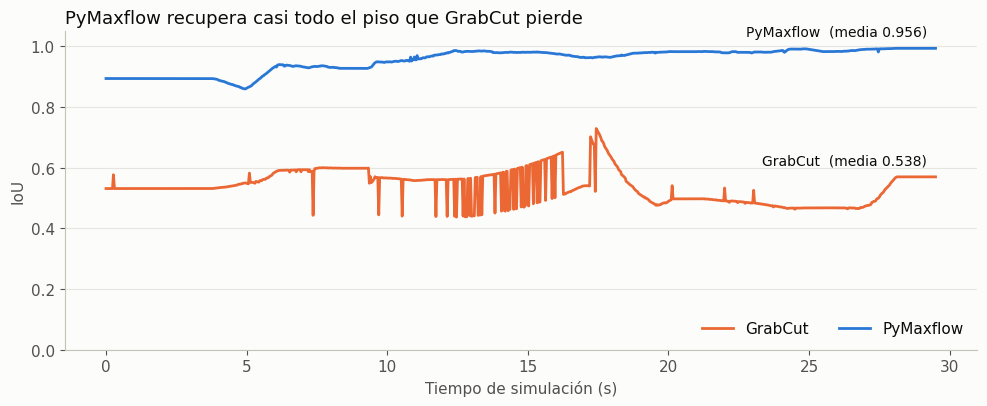

In [5]:
t0 = int(stamps[0]) / 1e9
fig, ax = plt.subplots(figsize=(10, 4.2))

for metodo, color in (("GrabCut", COLOR_GRABCUT), ("PyMaxflow", COLOR_MAXFLOW)):
    d = df[df["metodo"] == metodo]
    t = d["stamp"].astype(np.int64).to_numpy() / 1e9 - t0
    ax.plot(t, d["iou"], color=color, linewidth=2, label=metodo)
    ax.annotate(f"{metodo}  (media {d['iou'].mean():.3f})", (t[-1], d["iou"].iloc[-1]),
                xytext=(-6, 9), textcoords="offset points", ha="right", color=TEXTO, fontsize=10)

ax.set_ylim(0, 1.05)
ax.set_xlabel("Tiempo de simulación (s)")
ax.set_ylabel("IoU")
ax.set_title("PyMaxflow recupera casi todo el piso que GrabCut pierde", loc="left", fontsize=13)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "iou_por_frame.png", dpi=150)
plt.show()

### Mapas de error

**Verde:** suelo detectado (TP). **Azul:** suelo perdido (FN). **Rojo:** obstáculo marcado como suelo (FP), el error peligroso para el robot.

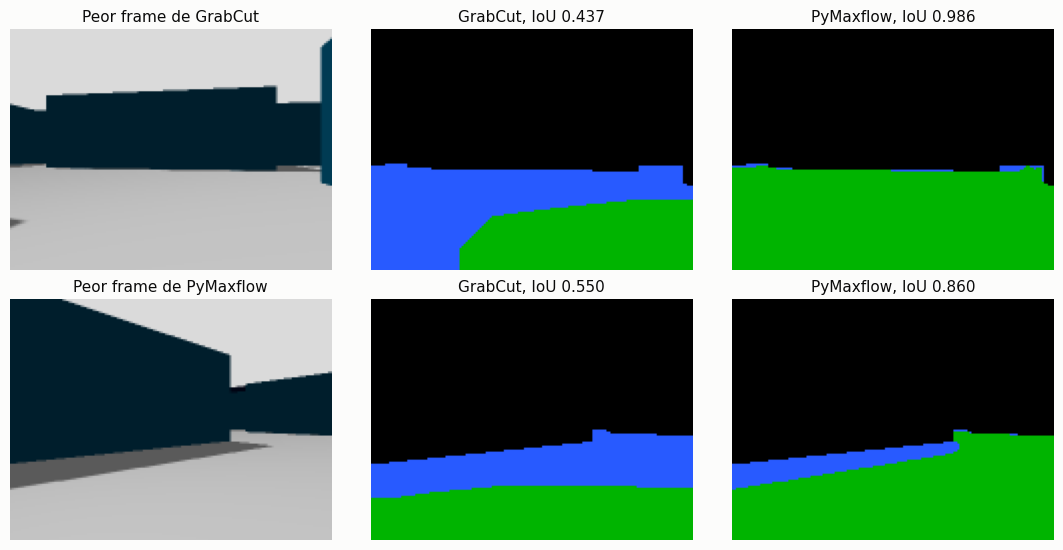

In [6]:
def mapa_errores(pred, gt):
    errores = np.zeros((*gt.shape, 3), dtype=np.uint8)
    errores[pred & gt] = (0, 180, 0)
    errores[~pred & gt] = (40, 90, 255)
    errores[pred & ~gt] = (230, 30, 30)
    return errores

d_mf = df[df["metodo"] == "PyMaxflow"].set_index("stamp")
d_gc = df[df["metodo"] == "GrabCut"].set_index("stamp")
casos = [("Peor frame de GrabCut", d_gc["iou"].idxmin()), ("Peor frame de PyMaxflow", d_mf["iou"].idxmin())]

fig, ax = plt.subplots(2, 3, figsize=(11, 5.6))
for fila, (nombre, stamp) in enumerate(casos):
    _, frame, gt_chico = preparar(stamp)
    ax[fila, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax[fila, 0].set_title(nombre, fontsize=11)
    ax[fila, 1].imshow(mapa_errores(mascaras_gc[stamp], gt_chico))
    ax[fila, 1].set_title(f"GrabCut, IoU {d_gc.loc[stamp, 'iou']:.3f}", fontsize=11)
    ax[fila, 2].imshow(mapa_errores(mascaras_mf[stamp], gt_chico))
    ax[fila, 2].set_title(f"PyMaxflow, IoU {d_mf.loc[stamp, 'iou']:.3f}", fontsize=11)
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "mapas_error.png", dpi=150)
plt.show()

## 6. Barrido de λ

Se evalúa 1 de cada 5 frames. Un IoU casi constante significa que, en este mundo, el término de datos ya separa bien las clases y la suavidad tiene poco que corregir.

In [7]:
lambda_original = seg.LAMBDA
muestra = stamps[::5]
filas_lambda = []
try:
    for valor in (0, 0.5, 1, 2, 5, 10, 20, 50):
        seg.LAMBDA = valor
        r, tiempos = [], []
        for stamp in muestra:
            _, frame, gt_chico = preparar(stamp)
            _, mask, _, _, ms = seg.procesar_graph_cuts_2(frame)
            r.append(metricas(mask > 0, gt_chico)); tiempos.append(ms)
        r = np.array(r)
        filas_lambda.append({"lambda": valor, "iou": r[:, 0].mean(), "precision": r[:, 1].mean(),
                             "recall": r[:, 2].mean(), "ms_mediana": np.median(tiempos)})
finally:
    seg.LAMBDA = lambda_original

barrido = pd.DataFrame(filas_lambda)
barrido.to_csv(DIR_RESULTADOS / "barrido_lambda.csv", index=False)
barrido.round(4)

,lambda,iou,precision,recall,ms_mediana
0,0.0,0.9548,0.9998,0.9550,7.9798
1,0.5,0.9555,0.9998,0.9557,8.0032
2,1.0,0.9555,0.9998,0.9557,7.7480
3,2.0,0.9556,0.9998,0.9557,8.4444
4,5.0,0.9556,0.9998,0.9558,8.1476
5,10.0,0.9558,0.9998,0.9560,7.6724
6,20.0,0.9562,0.9998,0.9564,7.8878
7,50.0,0.9569,0.9998,0.9571,9.3585


## 7. Videos

- `comparacion_maze.mp4`: original, ground truth, GrabCut y PyMaxflow.
- `errores_maze.mp4`: original y mapa de errores de cada método.

In [8]:
def escribir_texto(img, texto, pos=(8, 22), escala=0.52):
    cv2.putText(img, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala, (255, 255, 255), 1, cv2.LINE_AA)
    return img

def a_panel(mascara):
    return cv2.resize(mascara.astype(np.uint8), TAM_PANEL, interpolation=cv2.INTER_NEAREST) > 0

def panel(rgb, mascara, titulo):
    salida = rgb.copy()
    if mascara is not None:
        verde = np.zeros_like(rgb)
        verde[mascara] = (0, 220, 0)
        mezcla = cv2.addWeighted(rgb, 0.6, verde, 0.4, 0)
        salida[mascara] = mezcla[mascara]
    return escribir_texto(salida, titulo)

def panel_error(pred, gt, titulo):
    img = cv2.cvtColor(mapa_errores(pred, gt), cv2.COLOR_RGB2BGR)
    img = cv2.resize(img, TAM_PANEL, interpolation=cv2.INTER_NEAREST)
    return escribir_texto(img, titulo)

def abrir_video(ruta, tam):
    video = cv2.VideoWriter(str(ruta), cv2.VideoWriter_fourcc(*"mp4v"), FPS_VIDEO, tam)
    if not video.isOpened():
        raise IOError(f"No se pudo crear {ruta}")
    return video

ruta_comp = DIR_VIDEOS / "comparacion_maze.mp4"
ruta_err = DIR_VIDEOS / "errores_maze.mp4"
video_comp = abrir_video(ruta_comp, (640, 480))
video_err = abrir_video(ruta_err, (960, 270))

leyenda = np.full((30, 960, 3), 24, dtype=np.uint8)
for x, color, texto in ((16, (0, 180, 0), "TP: suelo detectado"), (300, (255, 90, 40), "FN: suelo perdido"),
                        (570, (30, 30, 230), "FP: obstaculo marcado como suelo")):
    cv2.rectangle(leyenda, (x, 9), (x + 12, 21), color, -1)
    cv2.putText(leyenda, texto, (x + 20, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (235, 235, 235), 1, cv2.LINE_AA)

for stamp in stamps:
    rgb, _, gt_chico = preparar(stamp)
    iou_gc, iou_mf = d_gc.loc[stamp, "iou"], d_mf.loc[stamp, "iou"]
    t_gc = f"GrabCut, IoU {iou_gc:.2f}"
    t_mf = f"PyMaxflow, IoU {iou_mf:.2f}"

    mosaico = np.vstack([
        np.hstack([panel(rgb, None, "Original"), panel(rgb, a_panel(gt_chico), "GT Gazebo")]),
        np.hstack([panel(rgb, a_panel(mascaras_gc[stamp]), t_gc), panel(rgb, a_panel(mascaras_mf[stamp]), t_mf)]),
    ])
    video_comp.write(mosaico)

    fila = np.hstack([panel(rgb, None, "Original"),
                      panel_error(mascaras_gc[stamp], gt_chico, t_gc),
                      panel_error(mascaras_mf[stamp], gt_chico, t_mf)])
    video_err.write(np.vstack([fila, leyenda]))

video_comp.release()
video_err.release()

for ruta in (ruta_comp, ruta_err):
    c = cv2.VideoCapture(str(ruta))
    n = int(c.get(cv2.CAP_PROP_FRAME_COUNT)); fps = c.get(cv2.CAP_PROP_FPS)
    ok, primero = c.read(); c.release()
    if not ok or n != len(stamps):
        raise RuntimeError(f"Video incompleto: {ruta.name} ({n} frames)")
    print(f"{ruta.name}: {n} frames, {fps:.0f} FPS, {primero.shape[1]}x{primero.shape[0]}, {ruta.stat().st_size / 1e6:.1f} MB")

if shutil.which("ffmpeg"):
    for ruta in (ruta_comp, ruta_err):
        destino = ruta.with_name(ruta.stem + "_h264.mp4")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(ruta), "-c:v", "libx264",
                        "-pix_fmt", "yuv420p", str(destino)], check=True)
        print("Convertido para compartir:", destino.name)
else:
    print("ffmpeg no está instalado: los videos quedan en mp4v (se abren con VLC).")

comparacion_maze.mp4: 886 frames, 30 FPS, 640x480, 3.7 MB
errores_maze.mp4: 886 frames, 30 FPS, 960x270, 2.5 MB
Convertido para compartir: comparacion_maze_h264.mp4
Convertido para compartir: errores_maze_h264.mp4
